# ¿Funciona el curso de Excel?

Evaluación de un curso de Excel de una plataforma de aprendizaje con un experimento aleatorizado.

> Los datos son sintéticos. Los generé con `datos/generar_datos.py` (semilla 2026) para practicar el método; no corresponden a ninguna empresa ni persona real.

Quería responder cinco preguntas:

1. ¿El grupo que hace el curso mejora más en un examen práctico de Excel que el grupo control? ¿Cuánto, y alcanza para que valga la pena?
2. ¿El resultado cambia si tomo en cuenta el nivel inicial, el cargo y la antigüedad?
3. ¿Los que completan más módulos mejoran más?
4. ¿Cuántos siguen estudiando 4, 8 y 12 semanas después del curso?
5. ¿Hay diferencias por cargo o área?

El diseño: 75 colaboradores se inscribieron de forma voluntaria y se sortearon en dos grupos, 36 para el curso y 39 para un grupo control en lista de espera (hacen el curso en un segundo ciclo). Todos dieron un examen práctico antes y otro después del curso, que duró 4 semanas (8 módulos). Después se siguió el uso de la plataforma hasta la semana 16.

## 0. Reglas que fijé antes de analizar

Antes de correr el análisis dejé por escrito cómo iba a decidir si el curso funciona (el detalle está en `PLAN_ANALISIS_PREVIO.md`). Lo hice después de mirar los promedios por encima, así que lo aclaro aquí.

- El curso funciona si el efecto ajustado es de **al menos 2.5 puntos sobre 20** y su intervalo de confianza al 95% no incluye el cero. Elegí 2.5 porque es el 12.5% de la escala: quería un cambio que se note en el examen, no solo uno estadísticamente significativo.
- Comparo a las personas según el grupo en el que salieron sorteadas, aunque no hayan terminado el curso (intención de tratar).
- Una persona está activa si tuvo al menos una sesión en la semana, y abandona si pasa 4 semanas seguidas sin entrar, contando desde la semana 5.
- Para las 6 personas sin examen final uso los casos completos y luego reviso dos escenarios alternativos.
- Módulos, cargo y área son exploratorios: no saco conclusiones causales de ahí.

Con el efecto y su intervalo, la conclusión sale de esta tabla:

| Efecto | Intervalo | Conclusión |
|---|---|---|
| 2.5 o más | no incluye el cero | El curso funciona |
| menos de 2.5 | no incluye el cero | Mejora real, pero menor a la relevante |
| 2.5 o más | incluye el cero | Prometedor, pero no concluyente |
| menos de 2.5 | incluye el cero | No hay evidencia de que funcione |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from utils_estadistica import (matriz_diseno, ols_hc3, prueba_f_anidada, smd_numerica,
                               smd_proporcion, ic_wilson, ic_diferencia_newcombe,
                               kaplan_meier, imputacion_multiple)

pd.set_option("display.precision", 2)
pd.set_option("display.max_columns", 20)

# Reglas del plan
UMBRAL_EXITO = 2.5        # puntos sobre 20
FIN_CURSO = 4             # el curso ocupa las semanas 1-4
ULTIMA_SEMANA = 16
SEMANAS_SIN_USO = 4       # semanas seguidas sin entrar = abandono
SEMANAS_CLAVE = [8, 12, 16]

# Colores y estilo de los gráficos
COLOR = {"Curso": "#2a78d6", "Control": "#eb6834"}
TINTA, TINTA_2, GRILLA = "#0b0b0b", "#52514e", "#e6e5e0"
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "axes.edgecolor": GRILLA, "axes.labelcolor": TINTA_2, "axes.titlecolor": TINTA,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelsize": 10, "xtick.color": TINTA_2, "ytick.color": TINTA_2,
    "xtick.labelsize": 9, "ytick.labelsize": 9, "axes.grid": True, "grid.color": GRILLA,
    "grid.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "legend.frameon": False, "legend.fontsize": 9, "font.size": 10, "lines.linewidth": 2,
})

def guardar(fig, nombre):
    fig.savefig(f"figuras/{nombre}.png", dpi=200, bbox_inches="tight")

## 1. Revisión de los datos

Antes de empezar reviso que los datos estén completos y sean coherentes: conteos, IDs únicos, puntajes entre 0 y 20 y que las dos tablas cuadren.

In [2]:
personas = pd.read_csv("datos/colaboradores_examenes.csv")
uso = pd.read_csv("datos/uso_plataforma_semanal.csv")

personas["curso"] = (personas["grupo"] == "Curso").astype(int)        # 1 = Curso, 0 = Control
personas["antiguedad_anios"] = personas["antiguedad_meses"] / 12
personas["mejora"] = personas["puntaje_post"] - personas["puntaje_pre"]

personas.head()

,id_colaborador,area,cargo,antiguedad_meses,grupo,modulos_completados,puntaje_pre,puntaje_post,curso,antiguedad_anios,mejora
0,C001,Operaciones,Analista,40,Curso,2.0,13.0,13.5,1,3.33,0.5
1,C002,Recursos Humanos,Asistente,51,Control,NaN,11.0,10.0,0,4.25,-1.0
2,C003,Comercial,Coordinador,86,Curso,7.0,7.0,12.5,1,7.17,5.5
3,C004,Finanzas,Asistente,24,Curso,8.0,11.0,14.0,1,2.00,3.0
4,C005,Finanzas,Asistente,18,Curso,8.0,10.0,12.5,1,1.50,2.5


In [3]:
# Si algo no cuadra, el notebook se detiene aquí
assert len(personas) == 75 and personas["id_colaborador"].is_unique
assert personas["grupo"].value_counts().to_dict() == {"Control": 39, "Curso": 36}
assert len(uso) == 75 * 16
assert set(uso["id_colaborador"]) == set(personas["id_colaborador"])
assert (uso.groupby("id_colaborador")["semana"].apply(sorted).apply(lambda s: s == list(range(1, 17)))).all()
assert personas["puntaje_pre"].between(0, 20).all()
assert personas["puntaje_post"].dropna().between(0, 20).all()
assert personas["puntaje_pre"].notna().all()
assert personas.loc[personas["grupo"] == "Control", "modulos_completados"].isna().all()
assert personas.loc[personas["grupo"] == "Curso", "modulos_completados"].between(0, 8).all()
assert (uso["sesiones"] >= 0).all() and (uso["horas_estudio"] >= 0).all()

print("Datos OK.\n")
print(f"Personas: {len(personas)}  |  Filas de uso semanal: {len(uso)}")
print(f"Curso: {(personas.grupo == 'Curso').sum()}  |  Control: {(personas.grupo == 'Control').sum()}")
sin_post = personas["puntaje_post"].isna()
print(f"Sin examen final: {sin_post.sum()} "
      f"(Curso {(sin_post & (personas.grupo == 'Curso')).sum()}, "
      f"Control {(sin_post & (personas.grupo == 'Control')).sum()})")
inconsistentes = ((uso["sesiones"] > 0) & (uso["horas_estudio"] == 0)).sum()
print(f"Semanas con sesiones pero 0 horas: {inconsistentes}")

Datos OK.

Personas: 75  |  Filas de uso semanal: 1200
Curso: 36  |  Control: 39
Sin examen final: 6 (Curso 4, Control 2)
Semanas con sesiones pero 0 horas: 0


## 2. ¿El sorteo dejó grupos parecidos?

Con 75 personas el sorteo puede dejar diferencias por azar, así que comparo los grupos antes del curso. Uso la diferencia estandarizada (SMD): la diferencia entre grupos dividida entre la desviación estándar. Tomo |SMD| > 0.2 como señal de que conviene ajustar por esa variable.

No uso valores p para esto. Si el sorteo fue real, cualquier diferencia es por azar, así que la pregunta útil no es si es significativa sino si es lo bastante grande como para sesgar la comparación.

In [4]:
curso = personas[personas["grupo"] == "Curso"]
control = personas[personas["grupo"] == "Control"]

filas = []
for col, etiqueta in [("puntaje_pre", "Puntaje inicial (0-20)"), ("antiguedad_meses", "Antigüedad (meses)")]:
    filas.append({"Variable": etiqueta,
                  "Curso (n=36)": f"{curso[col].mean():.1f} (DE {curso[col].std():.1f})",
                  "Control (n=39)": f"{control[col].mean():.1f} (DE {control[col].std():.1f})",
                  "SMD": smd_numerica(curso[col], control[col])})
for col, nombre in [("cargo", "Cargo"), ("area", "Área")]:
    for nivel in sorted(personas[col].unique()):
        pa, pb = (curso[col] == nivel).mean(), (control[col] == nivel).mean()
        filas.append({"Variable": f"{nombre}: {nivel}",
                      "Curso (n=36)": f"{(curso[col] == nivel).sum()} ({pa:.0%})",
                      "Control (n=39)": f"{(control[col] == nivel).sum()} ({pb:.0%})",
                      "SMD": smd_proporcion(pa, pb)})

balance = pd.DataFrame(filas)
balance["Desequilibrio"] = np.select([balance["SMD"].abs() > 0.2, balance["SMD"].abs() > 0.1],
                                     ["Sí (>0.2)", "Leve (0.1-0.2)"], "No")
balance.round({"SMD": 2})

,Variable,Curso (n=36),Control (n=39),SMD,Desequilibrio
0,Puntaje inicial (0-20),10.1 (DE 2.9),9.8 (DE 3.0),0.10,No
1,Antigüedad (meses),40.8 (DE 39.1),38.3 (DE 26.7),0.08,No
2,Cargo: Analista,12 (33%),21 (54%),-0.42,Sí (>0.2)
3,Cargo: Asistente,18 (50%),14 (36%),0.29,Sí (>0.2)
4,Cargo: Coordinador,6 (17%),4 (10%),0.19,Leve (0.1-0.2)
5,Área: Administración,5 (14%),4 (10%),0.11,Leve (0.1-0.2)
6,Área: Comercial,10 (28%),11 (28%),-0.01,No
7,Área: Finanzas,7 (19%),11 (28%),-0.21,Sí (>0.2)
8,Área: Logística,5 (14%),2 (5%),0.30,Sí (>0.2)
9,Área: Operaciones,7 (19%),4 (10%),0.26,Sí (>0.2)


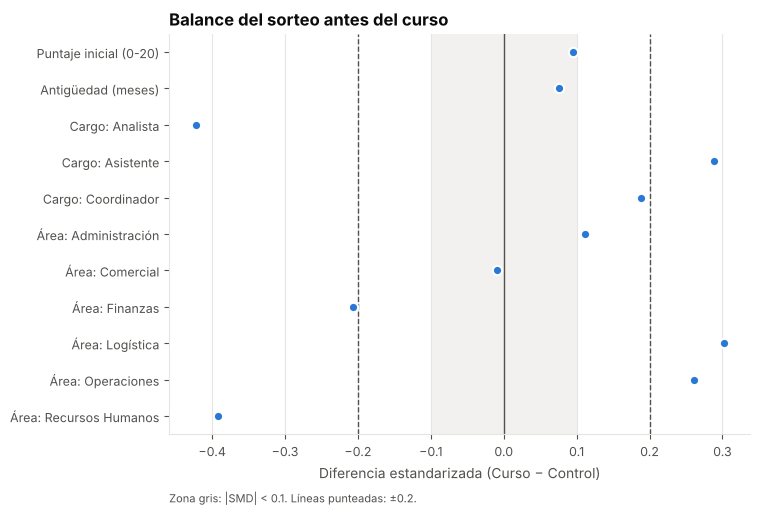

In [5]:
fig, ax = plt.subplots(figsize=(7.5, 5.2))
b = balance.iloc[::-1].reset_index(drop=True)
ax.axvspan(-0.1, 0.1, color=GRILLA, alpha=0.5, lw=0)
ax.axvline(0, color=TINTA_2, lw=1)
for x in (-0.2, 0.2):
    ax.axvline(x, color=TINTA_2, lw=1, ls="--")
ax.scatter(b["SMD"], b.index, s=45, color=COLOR["Curso"], zorder=3, edgecolor="white", linewidth=1.5)
ax.set_yticks(b.index, b["Variable"])
ax.grid(axis="y", visible=False)
ax.set_xlabel("Diferencia estandarizada (Curso − Control)")
ax.set_title("Balance del sorteo antes del curso")
ax.text(0, -0.17, "Zona gris: |SMD| < 0.1. Líneas punteadas: ±0.2.",
        fontsize=8, color=TINTA_2, transform=ax.transAxes)
guardar(fig, "01_balance")

El puntaje inicial y la antigüedad quedaron parejos (SMD de 0.10 y 0.08). Donde sí hay diferencia es en el cargo: en el control hay más analistas (54% contra 33%) y en el curso, más asistentes (50% contra 36%). También hay diferencias en algunas áreas, pero con muy pocas personas por área.

Por eso el modelo principal incluye el cargo y la antigüedad. El área la dejo para la sección 7.

## 3. Efecto del curso en el examen

Voy de lo más simple a lo más completo: primero los promedios, luego una prueba t sobre la mejora y al final una regresión que controla el nivel inicial, el cargo y la antigüedad. Aquí uso las 69 personas que dieron los dos exámenes; en la sección 4 reviso qué pasa con las 6 que faltan.

### Promedios antes y después

In [6]:
completos = personas.dropna(subset=["puntaje_post"]).copy()

descriptivo = (completos.groupby("grupo")
               .agg(n=("id_colaborador", "count"),
                    pre=("puntaje_pre", "mean"),
                    post=("puntaje_post", "mean"),
                    mejora=("mejora", "mean"),
                    de_mejora=("mejora", "std"))
               .loc[["Curso", "Control"]])
diferencia_bruta = descriptivo.loc["Curso", "mejora"] - descriptivo.loc["Control", "mejora"]
print(f"Diferencia de mejoras (Curso − Control): {diferencia_bruta:.2f} puntos")
descriptivo

Diferencia de mejoras (Curso − Control): 1.84 puntos


,n,pre,post,mejora,de_mejora
grupo,,,,,
Curso,32,10.33,12.42,2.09,1.84
Control,37,9.96,10.22,0.26,1.76


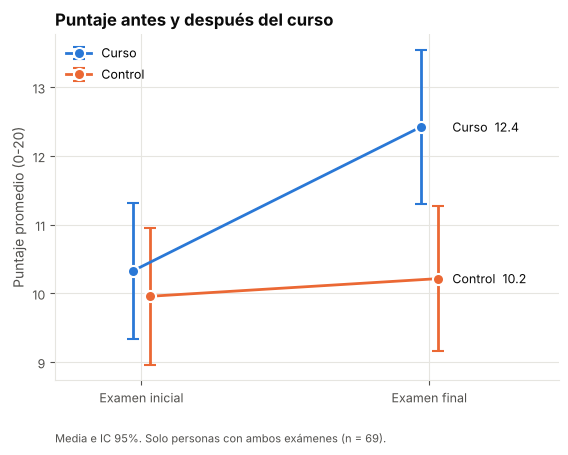

In [7]:
def media_ic(x):
    x = np.asarray(x, float)
    m, ee = x.mean(), x.std(ddof=1) / np.sqrt(len(x))
    q = stats.t.ppf(0.975, len(x) - 1)
    return m, m - q * ee, m + q * ee

fig, ax = plt.subplots(figsize=(6.5, 4.5))
xs = [0, 1]
for g, dx in [("Curso", -0.03), ("Control", 0.03)]:
    d = completos[completos["grupo"] == g]
    vals = [media_ic(d["puntaje_pre"]), media_ic(d["puntaje_post"])]
    medias = [v[0] for v in vals]
    err = [[v[0] - v[1] for v in vals], [v[2] - v[0] for v in vals]]
    ax.errorbar([x + dx for x in xs], medias, yerr=err, color=COLOR[g], marker="o", markersize=8,
                capsize=4, lw=2, markeredgecolor="white", markeredgewidth=1.5, label=g)
    ax.text(1.08, medias[1], f"{g}  {medias[1]:.1f}", color=TINTA, va="center", fontsize=9)
ax.set_xticks(xs, ["Examen inicial", "Examen final"])
ax.set_xlim(-0.3, 1.45)
ax.set_ylabel("Puntaje promedio (0-20)")
ax.set_title("Puntaje antes y después del curso")
ax.legend(loc="upper left")
ax.text(-0.3, ax.get_ylim()[0] - 0.9, "Media e IC 95%. Solo personas con ambos exámenes (n = 69).",
        fontsize=8, color=TINTA_2)
guardar(fig, "02_antes_despues")

Los dos grupos empiezan casi igual (10.3 y 10.0). El grupo curso sube 2.1 puntos y el control, 0.3. El control también mejora un poco porque repitió el examen; esa es la mejora que habría pasado igual sin el curso. La diferencia entre los dos es de 1.84 puntos.

### Prueba t sobre la mejora

Comparo la mejora (examen final menos inicial) entre grupos con la prueba t de Welch, que no asume que los dos grupos tengan la misma varianza.

In [8]:
mejora_curso = completos.loc[completos["grupo"] == "Curso", "mejora"]
mejora_control = completos.loc[completos["grupo"] == "Control", "mejora"]
welch = stats.ttest_ind(mejora_curso, mejora_control, equal_var=False)
ic_welch = welch.confidence_interval(0.95)
print(f"Diferencia de mejoras: {mejora_curso.mean() - mejora_control.mean():.2f} puntos")
print(f"IC 95%: [{ic_welch.low:.2f}, {ic_welch.high:.2f}]")
print(f"t = {welch.statistic:.2f}, gl = {welch.df:.1f}, p = {welch.pvalue:.4f}")

Diferencia de mejoras: 1.84 puntos
IC 95%: [0.97, 2.71]
t = 4.22, gl = 64.7, p = 0.0001


### Regresión con el puntaje inicial (ANCOVA)

Predigo el puntaje final con el grupo y el puntaje inicial. El coeficiente de `curso` indica cuántos puntos más saca alguien del curso frente a alguien del control que empezó con la misma nota. A este modelo también se le llama ANCOVA. Uso errores estándar robustos (HC3) porque con muestras chicas son más confiables.

In [9]:
X_simple = matriz_diseno(completos, numericas=["curso", "puntaje_pre"])
m_simple = ols_hc3(completos["puntaje_post"], X_simple)
print(f"n = {m_simple.n}  |  R² = {m_simple.r2:.2f}")
m_simple.tabla.round(3)

n = 69  |  R² = 0.72


,coef,error_est,t,p,ic_inf,ic_sup
Intercepto,1.23,0.84,1.46,0.15,-0.45,2.91
curso,1.87,0.45,4.19,0.00,0.98,2.77
puntaje_pre,0.90,0.08,11.24,0.00,0.74,1.06


### Regresión ajustada (estimación principal)

Agrego el cargo (referencia: asistente) y la antigüedad en años para corregir el desequilibrio que dejó el sorteo. Si el efecto casi no cambia, ese desequilibrio no estaba moviendo el resultado. No incluyo el área porque son 6 categorías con pocas personas cada una.

In [10]:
X_ajustado = matriz_diseno(completos, numericas=["curso", "puntaje_pre", "antiguedad_anios"],
                           categoricas={"cargo": "Asistente"})
m_ajustado = ols_hc3(completos["puntaje_post"], X_ajustado)
efecto = m_ajustado.efecto("curso")
print(f"n = {m_ajustado.n}  |  R² = {m_ajustado.r2:.2f}")
print(f"\nEfecto del curso: {efecto.coef:.2f} puntos  (IC 95%: {efecto.ic_inf:.2f} a {efecto.ic_sup:.2f}; p = {efecto.p:.4f})")
m_ajustado.tabla.round(3)

n = 69  |  R² = 0.74

Efecto del curso: 1.76 puntos  (IC 95%: 0.81 a 2.71; p = 0.0004)


,coef,error_est,t,p,ic_inf,ic_sup
Intercepto,1.75,0.86,2.04,0.05,0.03,3.46
curso,1.76,0.47,3.71,0.00,0.81,2.71
puntaje_pre,0.89,0.09,9.54,0.00,0.70,1.07
antiguedad_anios,-0.22,0.12,-1.88,0.07,-0.46,0.01
cargo[Analista],0.30,0.54,0.55,0.58,-0.78,1.38
cargo[Coordinador],2.18,0.99,2.19,0.03,0.19,4.16


Shapiro-Wilk sobre los residuos: W = 0.979, p = 0.281


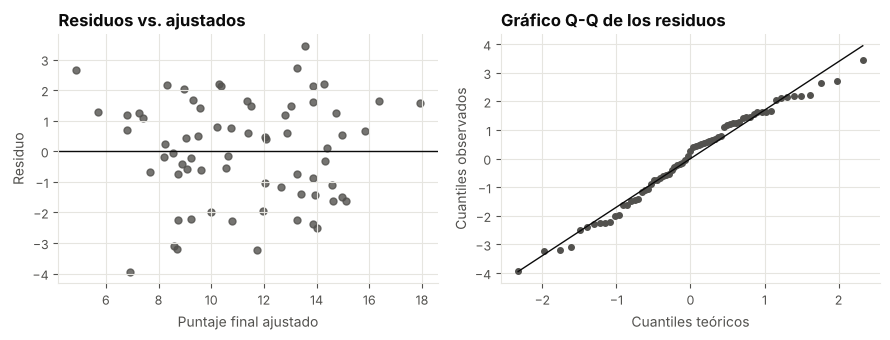

In [11]:
# Revisión de los residuos
fig, axs = plt.subplots(1, 2, figsize=(9, 3.5))
axs[0].scatter(m_ajustado.ajustados, m_ajustado.residuos, s=25, color=TINTA_2, alpha=0.8)
axs[0].axhline(0, color=TINTA, lw=1)
axs[0].set_xlabel("Puntaje final ajustado"); axs[0].set_ylabel("Residuo")
axs[0].set_title("Residuos vs. ajustados")
stats.probplot(m_ajustado.residuos, dist="norm", plot=axs[1])
axs[1].get_lines()[0].set(color=TINTA_2, markersize=4)
axs[1].get_lines()[1].set(color=TINTA, lw=1)
axs[1].set_title("Gráfico Q-Q de los residuos"); axs[1].set_xlabel("Cuantiles teóricos"); axs[1].set_ylabel("Cuantiles observados")
fig.tight_layout()
sw = stats.shapiro(m_ajustado.residuos)
print(f"Shapiro-Wilk sobre los residuos: W = {sw.statistic:.3f}, p = {sw.pvalue:.3f}")

In [12]:
comparacion = pd.DataFrame([
    {"Método": "Prueba t sobre la mejora", "Efecto": mejora_curso.mean() - mejora_control.mean(),
     "IC inf": ic_welch.low, "IC sup": ic_welch.high},
    {"Método": "Regresión con puntaje inicial", "Efecto": m_simple.efecto("curso").coef,
     "IC inf": m_simple.efecto("curso").ic_inf, "IC sup": m_simple.efecto("curso").ic_sup},
    {"Método": "Regresión ajustada (principal)", "Efecto": efecto.coef,
     "IC inf": efecto.ic_inf, "IC sup": efecto.ic_sup},
])
comparacion["Ancho IC"] = comparacion["IC sup"] - comparacion["IC inf"]
comparacion.round(2)

,Método,Efecto,IC inf,IC sup,Ancho IC
0,Prueba t sobre la mejora,1.84,0.97,2.71,1.74
1,Regresión con puntaje inicial,1.87,0.98,2.77,1.78
2,Regresión ajustada (principal),1.76,0.81,2.71,1.90


Las tres formas de calcularlo dan casi lo mismo: entre 1.76 y 1.87 puntos. Al ajustar por cargo y antigüedad el efecto baja apenas de 1.87 a 1.76, así que la diferencia de cargos entre los grupos no explica el resultado (pregunta 2).

Esperaba que la regresión diera un intervalo más angosto que la prueba t, pero no fue así. El coeficiente del puntaje inicial es 0.90, muy cerca de 1, y en ese caso comparar mejoras ya funciona casi igual de bien. Los residuos no muestran patrones raros y son compatibles con una distribución normal (Shapiro-Wilk p = 0.28).

### Tamaño del efecto

Calculo la d de Cohen dividiendo el efecto entre la desviación estándar del examen inicial. No uso la desviación de la mejora porque es más chica y haría ver el efecto más grande de lo que es.

In [13]:
n_cu, n_co = len(curso), len(control)
de_pre = np.sqrt(((n_cu - 1) * curso["puntaje_pre"].var() + (n_co - 1) * control["puntaje_pre"].var())
                 / (n_cu + n_co - 2))
d_cohen = efecto.coef / de_pre
print(f"Desviación estándar del examen inicial: {de_pre:.2f}")
print(f"d de Cohen: {d_cohen:.2f}  (IC 95%: {efecto.ic_inf / de_pre:.2f} a {efecto.ic_sup / de_pre:.2f})")
print(f"En la escala del examen: {efecto.coef:.2f} de 20 puntos = {efecto.coef / 20:.1%}")
print(f"El umbral de 2.5 puntos equivale a d = {UMBRAL_EXITO / de_pre:.2f}")

Desviación estándar del examen inicial: 2.91
d de Cohen: 0.60  (IC 95%: 0.28 a 0.93)
En la escala del examen: 1.76 de 20 puntos = 8.8%
El umbral de 2.5 puntos equivale a d = 0.86


### ¿Cumple el criterio?

In [14]:
def decidir(coef, ic_inf, ic_sup, umbral=UMBRAL_EXITO):
    if ic_sup < 0:
        return "El curso empeora el resultado"
    ic_sin_cero = ic_inf > 0
    if coef >= umbral and ic_sin_cero:
        return "El curso funciona según el criterio"
    if coef < umbral and ic_sin_cero:
        return "Mejora real, pero menor a la relevante"
    if coef >= umbral:
        return "Prometedor pero no concluyente"
    return "No hay evidencia de que funcione"

decision_principal = decidir(efecto.coef, efecto.ic_inf, efecto.ic_sup)
print(f"Efecto ajustado: {efecto.coef:.2f} puntos  |  IC 95%: [{efecto.ic_inf:.2f}, {efecto.ic_sup:.2f}]")
print(f"¿Efecto de {UMBRAL_EXITO} o más?  {'Sí' if efecto.coef >= UMBRAL_EXITO else 'No'}")
print(f"¿IC sin el cero?  {'Sí' if efecto.ic_inf > 0 else 'No'}")
print(f"\nConclusión: {decision_principal}")

Efecto ajustado: 1.76 puntos  |  IC 95%: [0.81, 2.71]
¿Efecto de 2.5 o más?  No
¿IC sin el cero?  Sí

Conclusión: Mejora real, pero menor a la relevante


No lo cumple. El efecto es de **1.76 puntos** (IC 95%: 0.81 a 2.71), con una d de 0.60. El intervalo no toca el cero, así que la mejora es real, pero el efecto estimado queda por debajo de los 2.5 puntos que puse como meta.

Hay que decir también que el límite superior del intervalo (2.71) pasa de 2.5. Con 75 personas no tengo precisión suficiente para descartar que el efecto real llegue a la meta.

## 4. ¿Cambian las cosas con las 6 personas que faltan?

Seis personas no dieron el examen final (4 del curso y 2 del control). Si las que faltaron del curso eran las menos motivadas, el análisis con casos completos podría exagerar el efecto. Lo reviso de dos maneras:

- **Imputación múltiple:** estimo la nota que habrían sacado a partir de su grupo, nota inicial, cargo y antigüedad, lo repito 50 veces y combino los resultados (reglas de Rubin). En el plan solo puse grupo, nota inicial y cargo; agregué la antigüedad para que la imputación use las mismas variables que el modelo.
- **Escenario pesimista:** asumo que los que faltaron del curso no mejoraron nada y que los del control mejoraron como el promedio de su grupo.

In [15]:
personas.loc[personas["puntaje_post"].isna(),
             ["id_colaborador", "grupo", "cargo", "puntaje_pre", "modulos_completados"]]

,id_colaborador,grupo,cargo,puntaje_pre,modulos_completados
7,C008,Curso,Analista,10.0,8.0
14,C015,Control,Coordinador,8.0,NaN
19,C020,Control,Analista,7.0,NaN
49,C050,Curso,Asistente,3.0,7.0
63,C064,Curso,Asistente,9.5,6.0
64,C065,Curso,Analista,11.0,5.0


In [16]:
X_todos = matriz_diseno(personas, numericas=["curso", "puntaje_pre", "antiguedad_anios"],
                        categoricas={"cargo": "Asistente"})

# Imputación múltiple
mi_coef, mi_ee, mi_gl, mi_inf, mi_sup, mi_p = imputacion_multiple(
    personas, "puntaje_post", X_todos, X_todos, "curso", m=50, semilla=2026)

# Escenario pesimista
pesimista = personas.copy()
falta = pesimista["puntaje_post"].isna()
mejora_media_control = mejora_control.mean()
pesimista.loc[falta & (pesimista["grupo"] == "Curso"), "puntaje_post"] = pesimista["puntaje_pre"]
pesimista.loc[falta & (pesimista["grupo"] == "Control"), "puntaje_post"] = (
    pesimista["puntaje_pre"] + mejora_media_control).clip(0, 20)
m_pesimista = ols_hc3(pesimista["puntaje_post"], X_todos)
ef_pes = m_pesimista.efecto("curso")

sensibilidad = pd.DataFrame([
    {"Análisis": "Casos completos (n = 69)", "Efecto": efecto.coef, "IC inf": efecto.ic_inf, "IC sup": efecto.ic_sup},
    {"Análisis": "Imputación múltiple (n = 75)", "Efecto": mi_coef, "IC inf": mi_inf, "IC sup": mi_sup},
    {"Análisis": "Escenario pesimista (n = 75)", "Efecto": ef_pes.coef, "IC inf": ef_pes.ic_inf, "IC sup": ef_pes.ic_sup},
])
sensibilidad["Conclusión"] = [decidir(r["Efecto"], r["IC inf"], r["IC sup"]) for _, r in sensibilidad.iterrows()]
sensibilidad.round(2)

,Análisis,Efecto,IC inf,IC sup,Conclusión
0,Casos completos (n = 69),1.76,0.81,2.71,"Mejora real, pero menor a la relevante"
1,Imputación múltiple (n = 75),1.76,0.83,2.69,"Mejora real, pero menor a la relevante"
2,Escenario pesimista (n = 75),1.57,0.68,2.46,"Mejora real, pero menor a la relevante"


La conclusión no cambia. Con imputación el efecto queda igual (1.76) y en el escenario pesimista baja a 1.57 (IC 0.68 a 2.46), todavía lejos de cero.

## 5. ¿Más módulos, más mejora?

Solo con el grupo curso. Esto no es causal: los módulos no se sortearon, y quien completa más probablemente está más motivado, lo que por sí solo ya puede subir la nota.

In [17]:
curso_c = completos[completos["grupo"] == "Curso"].copy()
curso_c["modulos"] = curso_c["modulos_completados"].astype(float)

print("Módulos completados (grupo Curso, n = 36):")
print(curso["modulos_completados"].value_counts().sort_index().to_string())
print(f"Promedio: {curso['modulos_completados'].astype(float).mean():.1f} de 8  |  "
      f"Completaron los 8: {(curso['modulos_completados'] == 8).sum()} personas")

X_dosis = matriz_diseno(curso_c, numericas=["modulos", "puntaje_pre"])
m_dosis = ols_hc3(curso_c["mejora"], X_dosis)
ef_mod = m_dosis.efecto("modulos")
print(f"\nCada módulo adicional se asocia con {ef_mod.coef:.2f} puntos más de mejora "
      f"(IC 95%: {ef_mod.ic_inf:.2f} a {ef_mod.ic_sup:.2f}; p = {ef_mod.p:.3f}; n = {m_dosis.n}).")
m_dosis.tabla.round(3)

Módulos completados (grupo Curso, n = 36):
modulos_completados
1.0     1
2.0     4
4.0     2
5.0     6
6.0     6
7.0    10
8.0     7
Promedio: 5.8 de 8  |  Completaron los 8: 7 personas

Cada módulo adicional se asocia con 0.12 puntos más de mejora (IC 95%: -0.25 a 0.49; p = 0.523; n = 32).


,coef,error_est,t,p,ic_inf,ic_sup
Intercepto,2.02,1.70,1.19,0.24,-1.46,5.49
modulos,0.12,0.18,0.65,0.52,-0.25,0.49
puntaje_pre,-0.06,0.13,-0.43,0.67,-0.33,0.21


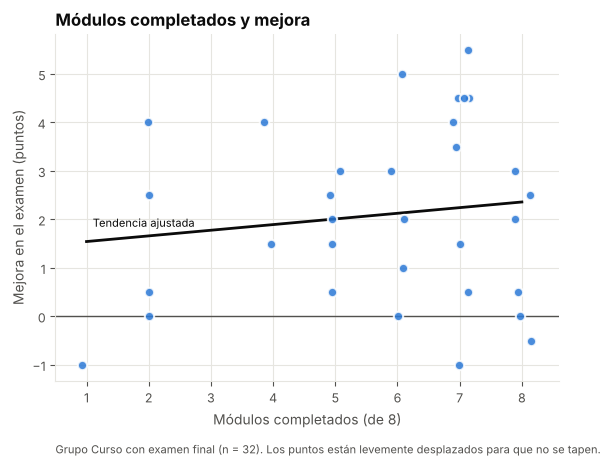

In [18]:
rng = np.random.default_rng(1)
fig, ax = plt.subplots(figsize=(6.5, 4.5))
x_j = curso_c["modulos"] + rng.uniform(-0.15, 0.15, len(curso_c))
ax.scatter(x_j, curso_c["mejora"], s=45, color=COLOR["Curso"], alpha=0.85, edgecolor="white", linewidth=1.5, zorder=3)
xs = np.linspace(curso_c["modulos"].min(), 8, 50)
b = m_dosis.tabla["coef"]
ax.plot(xs, b["Intercepto"] + b["modulos"] * xs + b["puntaje_pre"] * curso_c["puntaje_pre"].mean(),
        color=TINTA, lw=2)
ax.axhline(0, color=TINTA_2, lw=1)
ax.set_xlabel("Módulos completados (de 8)")
ax.set_ylabel("Mejora en el examen (puntos)")
ax.set_title("Módulos completados y mejora")
ax.text(1.1, b["Intercepto"] + b["modulos"] * 1 + b["puntaje_pre"] * curso_c["puntaje_pre"].mean() + 0.25,
        "Tendencia ajustada", fontsize=8, color=TINTA, va="bottom")
ax.set_xlim(0.5, 8.6)
ax.text(0, -0.21, "Grupo Curso con examen final (n = 32). Los puntos están levemente desplazados para que no se tapen.",
        fontsize=8, color=TINTA_2, transform=ax.transAxes)
guardar(fig, "03_modulos_mejora")

No encontré una relación clara: cada módulo extra se asocia con 0.12 puntos más, con un intervalo que va de −0.25 a 0.49. Además, casi todos completaron 5 módulos o más (29 de 36), así que hay poca variación para comparar. Para saber qué módulos sirven haría falta otro diseño, por ejemplo sortear una versión corta y una larga del curso.

## 6. ¿Se mantiene el hábito de estudio?

Cuento como activa a una persona que tuvo al menos una sesión en la semana. Para cada semana calculo el porcentaje de activos por grupo con su intervalo de confianza de Wilson, que funciona mejor que la fórmula clásica con grupos chicos o porcentajes cercanos a cero.

Para el hábito no fijé un umbral de éxito, porque ya había visto estos porcentajes por encima. Lo presento tal cual.

In [19]:
uso = uso.merge(personas[["id_colaborador", "grupo"]], on="id_colaborador")
uso["activo"] = uso["sesiones"] > 0

semanal = (uso.groupby(["grupo", "semana"])
           .agg(activos=("activo", "sum"), n=("activo", "size"))
           .reset_index())
semanal["pct"] = semanal["activos"] / semanal["n"]
ics = [ic_wilson(a, n) for a, n in zip(semanal["activos"], semanal["n"])]
semanal["ic_inf"] = [i[0] for i in ics]
semanal["ic_sup"] = [i[1] for i in ics]

(semanal.pivot(index="semana", columns="grupo", values="pct")[["Curso", "Control"]] * 100).round(0).T

semana,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16
grupo,,,,,,,,,,,,,,,,
Curso,81.0,78.0,72.0,64.0,64.0,50.0,44.0,44.0,39.0,39.0,33.0,19.0,14.0,22.0,17.0,19.0
Control,3.0,8.0,8.0,13.0,13.0,3.0,15.0,8.0,3.0,13.0,3.0,5.0,13.0,15.0,0.0,18.0


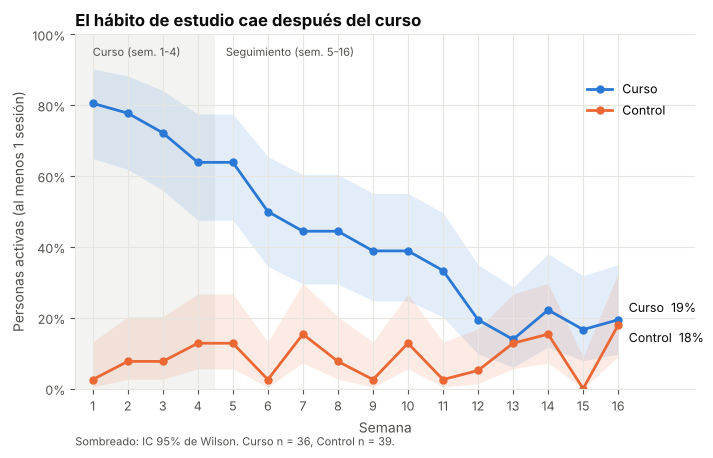

In [20]:
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.axvspan(0.5, FIN_CURSO + 0.5, color=GRILLA, alpha=0.45, lw=0)
ax.text(1, 0.97, "Curso (sem. 1-4)", fontsize=8, color=TINTA_2, va="top")
ax.text(FIN_CURSO + 0.8, 0.97, "Seguimiento (sem. 5-16)", fontsize=8, color=TINTA_2, va="top")
for g, desplaza in [("Curso", 0.035), ("Control", -0.035)]:
    d = semanal[semanal["grupo"] == g]
    ax.fill_between(d["semana"], d["ic_inf"], d["ic_sup"], color=COLOR[g], alpha=0.13, lw=0)
    ax.plot(d["semana"], d["pct"], color=COLOR[g], marker="o", markersize=5, label=g)
    ultimo = d.iloc[-1]
    ax.text(16.3, ultimo["pct"] + desplaza, f"{g}  {ultimo['pct']:.0%}", color=TINTA, va="center", fontsize=9)
ax.text(0, -0.16, "Sombreado: IC 95% de Wilson. Curso n = 36, Control n = 39.",
        fontsize=8, color=TINTA_2, transform=ax.transAxes)
ax.set_xlim(0.5, 18.2)
ax.set_ylim(0, 1)
ax.set_xticks(range(1, 17))
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.set_xlabel("Semana")
ax.set_ylabel("Personas activas (al menos 1 sesión)")
ax.set_title("El hábito de estudio cae después del curso")
ax.legend(loc="upper right", bbox_to_anchor=(0.97, 0.9))
guardar(fig, "04_habito_semanal")

Para comparar los grupos en las semanas clave uso el intervalo de Newcombe para la diferencia de porcentajes y la prueba exacta de Fisher, que funcionan bien con conteos chicos.

In [21]:
filas = []
for s in [FIN_CURSO] + SEMANAS_CLAVE:
    a = semanal.set_index(["grupo", "semana"])
    xc, nc = a.loc[("Curso", s), ["activos", "n"]]
    xk, nk = a.loc[("Control", s), ["activos", "n"]]
    lo, hi = ic_diferencia_newcombe(xc, nc, xk, nk)
    p_fisher = stats.fisher_exact([[xc, nc - xc], [xk, nk - xk]]).pvalue
    filas.append({"Semana": s,
                  "Momento": "Fin del curso" if s == FIN_CURSO else f"{s - FIN_CURSO} sem. después",
                  "Curso": f"{xc}/{nc} ({xc / nc:.0%})",
                  "Control": f"{xk}/{nk} ({xk / nk:.0%})",
                  "Diferencia (pp)": 100 * (xc / nc - xk / nk),
                  "IC inf (pp)": 100 * lo, "IC sup (pp)": 100 * hi, "p (Fisher)": p_fisher})
habito_clave = pd.DataFrame(filas)
habito_clave.round(3)

,Semana,Momento,Curso,Control,Diferencia (pp),IC inf (pp),IC sup (pp),p (Fisher)
0,4,Fin del curso,23/36 (64%),5/39 (13%),51.07,29.64,66.50,0.00
1,8,4 sem. después,16/36 (44%),3/39 (8%),36.75,17.22,53.50,0.00
2,12,8 sem. después,7/36 (19%),2/39 (5%),14.32,-0.92,30.34,0.08
3,16,12 sem. después,7/36 (19%),7/39 (18%),1.50,-16.13,19.48,1.00


Mientras dura el curso, el grupo curso está muy por encima del control (64% contra 13% en la semana 4). Después la diferencia se va cerrando:

- 4 semanas después: 44% contra 8% (diferencia de 37 puntos, IC 17 a 54).
- 8 semanas después: 19% contra 5% (14 puntos, IC −1 a 30). Ya no es concluyente.
- 12 semanas después: 19% contra 18%. Ya no hay diferencia.

### ¿Cuándo abandonan?

Considero que alguien abandona cuando pasa 4 semanas seguidas sin sesiones, desde la semana 5, y lo fecho en la primera semana de esa racha. Una racha que empieza en la semana 14 o después no llega a completar 4 semanas antes de que terminen los datos, así que quien no abandonó hasta la semana 13 queda censurado ahí: sé que siguió hasta esa semana, pero no qué pasó después. La curva de Kaplan-Meier usa esa información sin inventar abandonos que no se vieron.

In [22]:
ULTIMA_OBSERVABLE = ULTIMA_SEMANA - SEMANAS_SIN_USO + 1     # semana 13

def semana_de_abandono(serie):
    """Primera semana (desde la 5) en que empieza una racha de 4 semanas sin sesiones."""
    for w in range(FIN_CURSO + 1, ULTIMA_OBSERVABLE + 1):
        if (serie.loc[w:w + SEMANAS_SIN_USO - 1] == 0).all():
            return w
    return np.nan

sesiones_curso = (uso[uso["grupo"] == "Curso"]
                  .pivot(index="id_colaborador", columns="semana", values="sesiones"))
abandono = pd.DataFrame({"semana_abandono": sesiones_curso.apply(semana_de_abandono, axis=1)})
abandono["evento"] = abandono["semana_abandono"].notna().astype(int)
abandono["tiempo"] = abandono["semana_abandono"].fillna(ULTIMA_OBSERVABLE)

km = kaplan_meier(abandono["tiempo"], abandono["evento"])
km.loc[0, "tiempo"] = FIN_CURSO
print(f"Grupo Curso: {len(abandono)} personas  |  abandonan: {abandono['evento'].sum()}  |  "
      f"siguen en la semana 13: {(abandono['evento'] == 0).sum()}")
mediana = km.loc[km["S"] <= 0.5, "tiempo"]
print("Mediana de abandono: " + (f"semana {mediana.iloc[0]:.0f} ({mediana.iloc[0] - FIN_CURSO:.0f} semanas después del curso)"
                                  if len(mediana) else "no se alcanza"))
print("\nAbandonos según la semana en que empiezan:")
print(abandono["semana_abandono"].value_counts().sort_index().astype(int).to_string())
km.round(3)

Grupo Curso: 36 personas  |  abandonan: 28  |  siguen en la semana 13: 8
Mediana de abandono: semana 10 (6 semanas después del curso)

Abandonos según la semana en que empiezan:
semana_abandono
5.0     9
6.0     2
7.0     2
8.0     1
9.0     2
10.0    5
11.0    5
12.0    2


,tiempo,en_riesgo,eventos,censurados,S,ic_inf,ic_sup
0,4.0,36,0,0,1.00,1.00,1.00
1,5.0,36,9,0,0.75,0.57,0.86
2,6.0,27,2,0,0.69,0.52,0.82
3,7.0,25,2,0,0.64,0.46,0.77
4,8.0,23,1,0,0.61,0.43,0.75
5,9.0,22,2,0,0.56,0.38,0.70
6,10.0,20,5,0,0.42,0.26,0.57
7,11.0,15,5,0,0.28,0.14,0.43
8,12.0,10,2,0,0.22,0.10,0.37
9,13.0,8,0,8,0.22,0.10,0.37


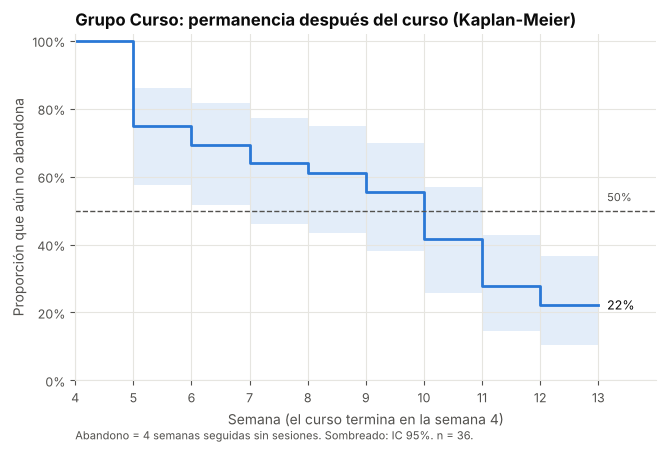

In [23]:
fig, ax = plt.subplots(figsize=(7.5, 4.5))
t = km["tiempo"].tolist() + [ULTIMA_OBSERVABLE]
s_ = km["S"].tolist() + [km["S"].iloc[-1]]
lo = km["ic_inf"].tolist() + [km["ic_inf"].iloc[-1]]
hi = km["ic_sup"].tolist() + [km["ic_sup"].iloc[-1]]
ax.fill_between(t, lo, hi, step="post", color=COLOR["Curso"], alpha=0.13, lw=0)
ax.step(t, s_, where="post", color=COLOR["Curso"], lw=2)
ax.axhline(0.5, color=TINTA_2, lw=1, ls="--")
ax.text(ULTIMA_OBSERVABLE + 0.15, 0.52, "50%", fontsize=8, color=TINTA_2, va="bottom")
ax.text(ULTIMA_OBSERVABLE + 0.15, s_[-1], f"{s_[-1]:.0%}", fontsize=9, color=TINTA, va="center")
ax.set_xlim(FIN_CURSO, ULTIMA_OBSERVABLE + 1)
ax.set_ylim(0, 1.02)
ax.set_xticks(range(FIN_CURSO, ULTIMA_OBSERVABLE + 1))
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.set_xlabel("Semana (el curso termina en la semana 4)")
ax.set_ylabel("Proporción que aún no abandona")
ax.set_title("Grupo Curso: permanencia después del curso (Kaplan-Meier)")
ax.text(FIN_CURSO, -0.17, "Abandono = 4 semanas seguidas sin sesiones. Sombreado: IC 95%. n = 36.",
        fontsize=8, color=TINTA_2, transform=ax.get_xaxis_transform())
guardar(fig, "05_kaplan_meier")

### Horas de estudio

Es el costo en tiempo del curso. El costo en dinero no está en los datos.

In [24]:
uso["etapa"] = np.where(uso["semana"] <= FIN_CURSO, "Curso (sem. 1-4)", "Seguimiento (sem. 5-16)")
horas_persona = (uso.groupby(["grupo", "etapa", "id_colaborador"])["horas_estudio"].sum().reset_index())
horas = (horas_persona.groupby(["grupo", "etapa"])["horas_estudio"]
         .agg(promedio="mean", mediana="median", minimo="min", maximo="max")
         .reindex(["Curso", "Control"], level=0))
horas_curso_1a4 = horas.loc[("Curso", "Curso (sem. 1-4)"), "promedio"]
horas_totales_1a4 = horas_persona.query("grupo == 'Curso' and etapa == 'Curso (sem. 1-4)'")["horas_estudio"].sum()
print(f"Horas promedio por persona del grupo Curso en las semanas 1-4: {horas_curso_1a4:.1f} "
      f"(unas {horas_curso_1a4 / FIN_CURSO:.1f} horas por semana)")
print(f"Horas totales del grupo Curso durante el curso: {horas_totales_1a4:.0f}")
horas.round(1)

Horas promedio por persona del grupo Curso en las semanas 1-4: 6.4 (unas 1.6 horas por semana)
Horas totales del grupo Curso durante el curso: 232


promedio  mediana  minimo  maximo
grupo   etapa                                                     
Curso   Curso (sem. 1-4)              6.4      6.6     0.9    14.0
        Seguimiento (sem. 5-16)       6.0      5.9     0.0    17.9
Control Curso (sem. 1-4)              0.3      0.0     0.0     3.4
        Seguimiento (sem. 5-16)       1.3      1.1     0.0     3.7

28 de las 36 personas abandonan antes de la semana 13, y 9 lo hacen apenas termina el curso. La mitad ya había abandonado en la semana 10, unas 6 semanas después del curso. En la semana 13 solo seguía el 22% (IC 10% a 37%).

En tiempo, cada persona del curso estudió 6.4 horas en promedio durante las 4 semanas: unas 1.6 horas por semana y 232 horas en total para el grupo.

## 7. Diferencias por cargo y área

Esta parte es exploratoria. Los grupos son muy chicos (por ejemplo, solo hay 4 coordinadores en el control), así que lo tomo como una mirada rápida y no saco conclusiones.

In [25]:
def tabla_por(col):
    t = (completos.groupby([col, "grupo"])["mejora"].agg(n="count", mejora="mean")
         .unstack("grupo"))
    t.columns = [f"{a} {b}" for a, b in t.columns]
    t = t[["n Curso", "n Control", "mejora Curso", "mejora Control"]]
    t["Diferencia"] = t["mejora Curso"] - t["mejora Control"]
    return t

print("Mejora promedio por cargo")
display(tabla_por("cargo").round(2))
print("Mejora promedio por área")
display(tabla_por("area").round(2))

Mejora promedio por cargo


,n Curso,n Control,mejora Curso,mejora Control,Diferencia
cargo,,,,,
Analista,10,20,1.75,0.15,1.60
Asistente,16,14,2.22,0.18,2.04
Coordinador,6,3,2.33,1.33,1.00


Mejora promedio por área


,n Curso,n Control,mejora Curso,mejora Control,Diferencia
area,,,,,
Administración,4,4,1.75,-0.12,1.88
Comercial,9,10,2.83,0.10,2.73
Finanzas,7,11,1.14,0.41,0.73
Logística,5,2,1.00,-1.00,2.00
Operaciones,5,3,2.70,1.00,1.70
Recursos Humanos,2,7,4.00,0.50,3.50


In [26]:
# ¿El efecto del curso cambia según el cargo? (interacción grupo × cargo)
X_inter = X_ajustado.copy()
for c in [c for c in X_ajustado.columns if c.startswith("cargo[")]:
    X_inter[f"curso × {c}"] = X_ajustado["curso"] * X_ajustado[c]
m_inter = ols_hc3(completos["puntaje_post"], X_inter)
F, gl1, gl2, p_inter = prueba_f_anidada(m_inter, m_ajustado)
print(f"Interacción grupo × cargo: F({gl1}, {gl2}) = {F:.2f}, p = {p_inter:.3f}")

Interacción grupo × cargo: F(2, 61) = 0.19, p = 0.830


El curso mejora más que el control en todos los cargos y áreas, con diferencias de entre 0.7 y 3.5 puntos, pero con tan pocas personas por grupo esas diferencias no dicen mucho. La interacción entre grupo y cargo no es significativa (p = 0.83), así que no hay señal de que el curso funcione distinto según el cargo.

## 8. Conclusiones y recomendación

In [27]:
resumen = pd.DataFrame([
    ("Efecto del curso (regresión ajustada)", f"{efecto.coef:.2f} puntos de 20 (IC 95%: {efecto.ic_inf:.2f} a {efecto.ic_sup:.2f})"),
    ("Tamaño del efecto", f"d = {d_cohen:.2f}"),
    ("Criterio de éxito", f"{UMBRAL_EXITO} puntos o más, con IC sin el cero"),
    ("Conclusión", decision_principal),
    ("Con datos faltantes", f"Imputación: {mi_coef:.2f}  |  Pesimista: {ef_pes.coef:.2f}"),
    ("Módulos (no causal)", f"+{ef_mod.coef:.2f} puntos por módulo (IC 95%: {ef_mod.ic_inf:.2f} a {ef_mod.ic_sup:.2f})"),
] + [
    (f"Activos semana {r['Semana']} ({r['Momento']})", f"Curso {r['Curso']}  vs.  Control {r['Control']}")
    for _, r in habito_clave.iterrows()
] + [
    ("Tiempo invertido (Curso, sem. 1-4)", f"{horas_curso_1a4:.1f} horas promedio por persona"),
], columns=["Indicador", "Resultado"])
resumen

,Indicador,Resultado
0,Efecto del curso (regresión ajustada),1.76 puntos de 20 (IC 95%: 0.81 a 2.71)
1,Tamaño del efecto,d = 0.60
2,Criterio de éxito,"2.5 puntos o más, con IC sin el cero"
3,Conclusión,"Mejora real, pero menor a la relevante"
4,Con datos faltantes,Imputación: 1.76 | Pesimista: 1.57
5,Módulos (no causal),+0.12 puntos por módulo (IC 95%: -0.25 a 0.49)
6,Activos semana 4 (Fin del curso),Curso 23/36 (64%) vs. Control 5/39 (13%)
7,Activos semana 8 (4 sem. después),Curso 16/36 (44%) vs. Control 3/39 (8%)
8,Activos semana 12 (8 sem. después),Curso 7/36 (19%) vs. Control 2/39 (5%)
9,Activos semana 16 (12 sem. después),Curso 7/36 (19%) vs. Control 7/39 (18%)


Para la recomendación también quería saber cuánta gente haría falta para tener una respuesta más precisa. Es una aproximación simple (el ancho del intervalo baja con la raíz del tamaño de muestra), no un cálculo formal de potencia.

In [28]:
semiancho = (efecto.ic_sup - efecto.ic_inf) / 2
objetivo = 0.5
n_aprox = m_ajustado.n * (semiancho / objetivo) ** 2
print(f"Precisión actual: ±{semiancho:.2f} puntos con n = {m_ajustado.n}")
print(f"Para una precisión de ±{objetivo} puntos harían falta unas {n_aprox:.0f} personas con ambos exámenes.")

Precisión actual: ±0.95 puntos con n = 69
Para una precisión de ±0.5 puntos harían falta unas 248 personas con ambos exámenes.


**El curso mejora el examen, pero menos de lo que me propuse, y el hábito no dura.**

1. El grupo curso sacó 1.76 puntos más que el control en el examen final (IC 95%: 0.81 a 2.71). Es una mejora real, pero no llega a los 2.5 puntos del criterio.
2. El resultado se mantiene al ajustar por cargo y antigüedad y en los dos escenarios de datos faltantes.
3. No hay una relación clara entre los módulos completados y la mejora.
4. El hábito se pierde: 44% seguía activo 4 semanas después de terminar, 19% a las 8 y 19% a las 12, igual que el control. La mitad abandona más o menos 6 semanas después del curso.
5. No hay diferencias claras por cargo.

**Recomendación:** no escalaría el curso así como está. Lo ajustaría y lo volvería a medir.

- El grupo control igual debería recibir el curso en el segundo ciclo, como estaba previsto. El curso sí enseña algo.
- Ese segundo ciclo sirve para probar una versión mejorada. Le agregaría actividades entre las semanas 5 y 12, que es cuando la gente deja de entrar (retos o casos del propio trabajo), y más práctica aplicada para acercarse a los 2.5 puntos. Son ideas a probar, no resultados.
- Con 75 personas el margen de error es de ±0.95 puntos. Para bajarlo a ±0.5 harían falta unas 250 personas.
- En tiempo, el curso costó 6.4 horas por persona (232 horas para el grupo). Falta el costo en dinero (licencias y horas de trabajo), que habría que pedir al área correspondiente.

## Limitaciones

- Los datos son sintéticos: sirven para mostrar el método, no dicen nada de un caso real.
- 75 personas es poco. Los intervalos son anchos y no alcanza para comparar subgrupos.
- Todos eran voluntarios, así que el resultado no se puede extender a toda la empresa.
- El examen no está validado y no se midió si la gente aplica lo aprendido en su trabajo.
- Puede haber efecto de práctica por repetir el examen (el grupo control lo descuenta) y efecto Hawthorne por saberse evaluados.
- La relación entre módulos y mejora no es causal.
- El umbral de 2.5 puntos lo fijé después de ver los promedios por encima.